# 04 - XGBoost

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and test XGBoost on the processed PhiUSIIL data (Experiment 1), compare different feature sets, and test the URL-only version on the external dataset (Experiment 2).

**About the model:** XGBoost builds many small decision trees one after another. Each new tree tries to fix the mistakes of the trees before it. It is often one of the best models for table data like ours, and it does not need scaling.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

sys.path.append(str(Path("..").resolve()))
from src.data import get_feature_sets, load_train_test, load_url_experiment, sample_rows
from src.features import extract_url_features
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_by_source,
    cross_validate_model,
    evaluate_model,
    fit_with_weights,
    make_cv,
    make_sample_weights,
    plot_confusion_matrix,
    save_results,
    tune_by_source,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 187,363 rows | 69 features
Test set:     46,841 rows | 69 features


## Model Settings

We use 300 trees. We try different tree depths (how many questions each tree can ask) and learning rates (how much each new tree changes the result). That gives 9 combinations. XGBoost is fast, so we tune on the full training set.

In [3]:
MODEL_NAME = "XGBoost"
model = XGBClassifier(n_estimators=300, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)

param_grid = {
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1, 0.2],
}

TUNING_SAMPLE_SIZE = None

## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'learning_rate': 0.05, 'max_depth': 4}
Best cross-validation F1: 1.0000


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [5]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,1.0,0.0
Precision,1.0,0.0
Recall,1.0,0.0
F1,1.0,0.0
ROC-AUC,1.0,0.0


### Learning Curve

A learning curve shows how the score changes when the model gets more training data. We use the best settings from tuning and 5-fold cross-validation on a sample of 50,000 training rows.

- **Training F1:** the score on the data the model was trained on.
- **Validation F1:** the score on data the model did not see.

How we read it (at the last point):

- **Overfitting:** the gap (training F1 − validation F1) is more than 0.01. The model memorises the training data.
- **Underfitting:** validation F1 is below 0.95 and the gap is small. The model is too simple to learn the pattern.
- **Good fit:** both lines are high and close together.

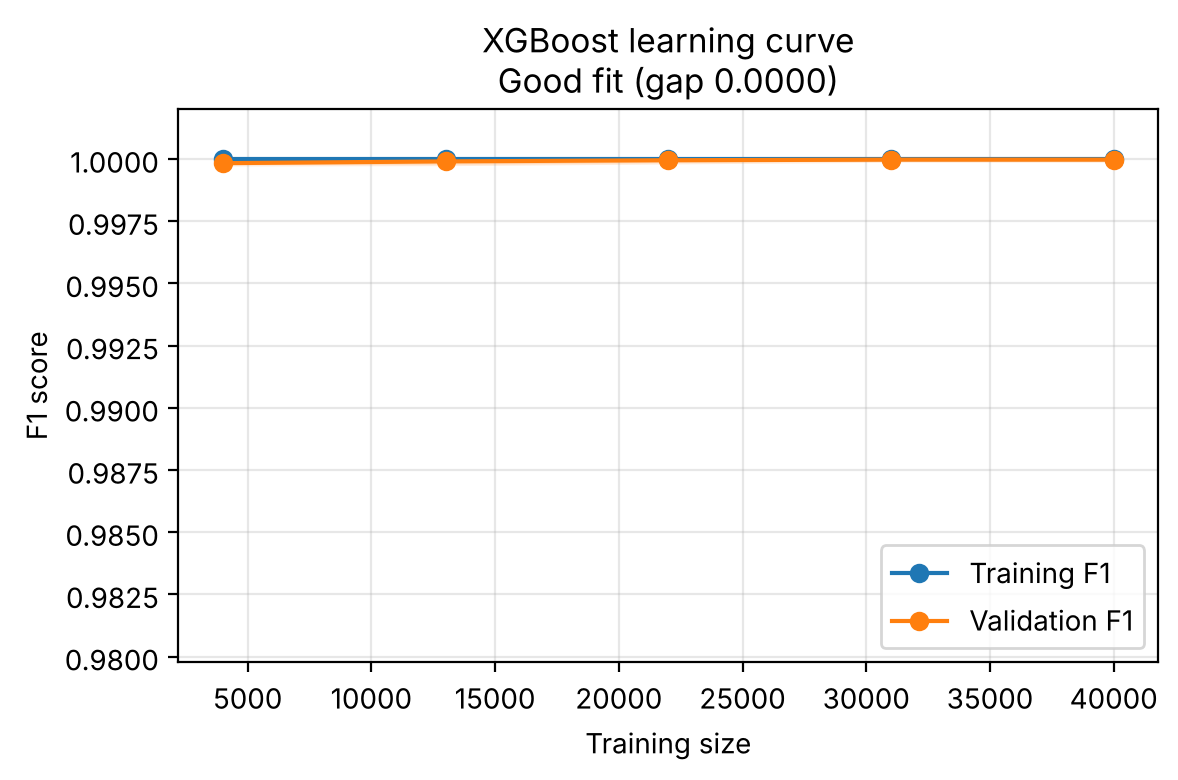

Result: Good fit (gap 0.0000)


,Training size,Training F1,Training Std,Validation F1,Validation Std
0,4000,1.0,0.0,0.9998,0.0001
1,13000,1.0,0.0,0.9999,0.0001
2,22000,1.0,0.0,1.0000,0.0001
3,31000,1.0,0.0,1.0000,0.0000
4,40000,1.0,0.0,1.0000,0.0000


In [ ]:
from src.evaluation import describe_fit, learning_curve_table, plot_learning_curve

X_curve, y_curve = sample_rows(X_train, y_train, 50000)
curve = learning_curve_table(best_model, X_curve, y_curve)
plot_learning_curve(curve, f"{MODEL_NAME} learning curve")

fit, gap = describe_fit(curve)
print(f"Result: {fit} (gap {gap:.4f})")
curve.round(4)

**Result: Good fit.**

- Training F1 and validation F1 are both 1.0000 at the last point, so the gap is 0.0000.
- With little data, the validation F1 is a little lower, and it goes up as we add more data.
- XGBoost is not overfitting: it works as well on unseen data as on the training data. This matches the cross-validation and test scores.

## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [6]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 2.8 seconds


,Test Score
Accuracy,1.0000
Precision,1.0000
Recall,0.9999
F1,0.9999
ROC-AUC,1.0000


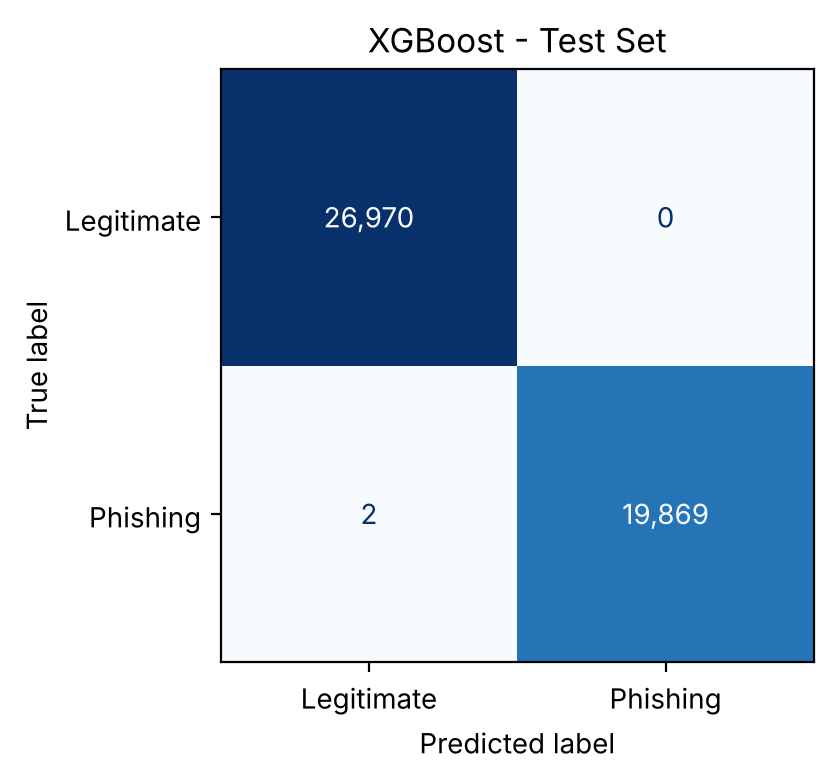

In [7]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

### Feature Importance

Tree models can tell us which features they used most to make decisions. We show the 15 most important features.

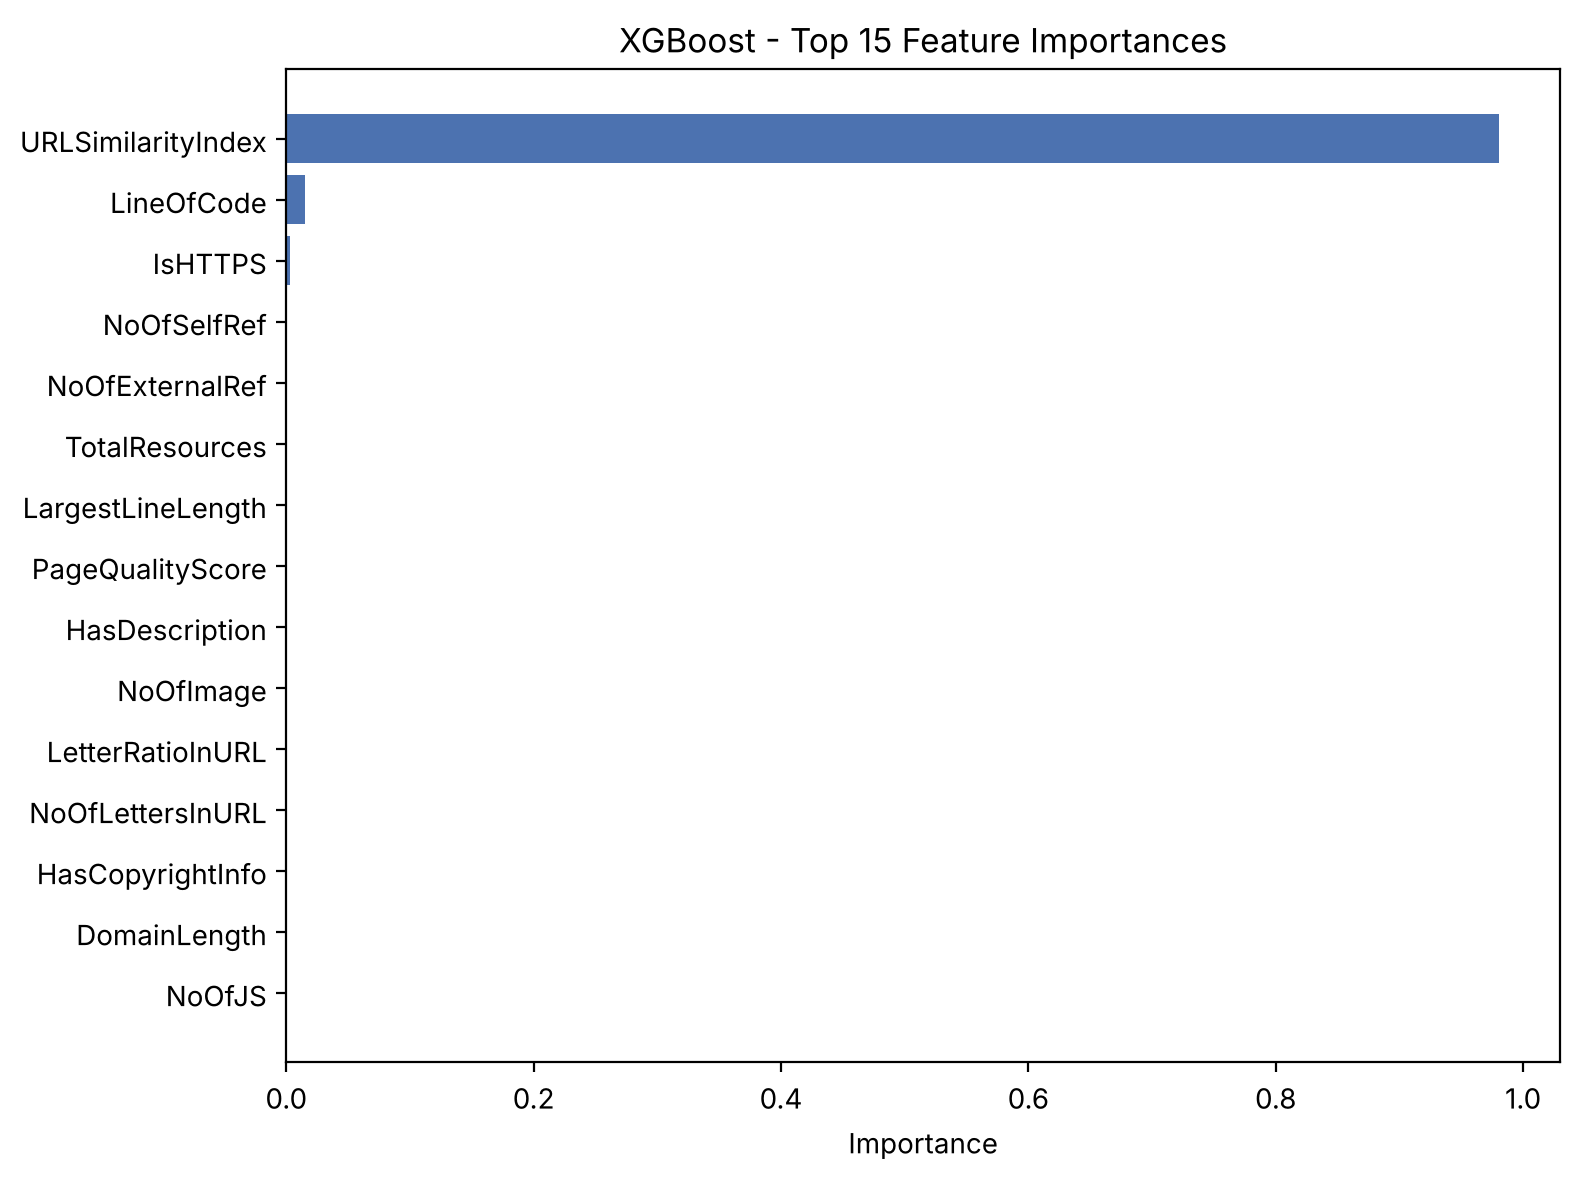

,Importance
URLSimilarityIndex,0.9808
LineOfCode,0.0149
IsHTTPS,0.0032
NoOfSelfRef,0.0003
NoOfExternalRef,0.0002
TotalResources,0.0001
LargestLineLength,0.0001
PageQualityScore,0.0001
HasDescription,0.0001
NoOfImage,0.0000


In [8]:
importance = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top_features = importance.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_features.index[::-1], top_features.values[::-1], color="#4C72B0")
ax.set_title(f"{MODEL_NAME} - Top 15 Feature Importances")
ax.set_xlabel("Importance")
fig.tight_layout()

save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "xgboost_feature_importance.png", dpi=300)
plt.show()

top_features.round(4).to_frame("Importance")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [9]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,1.0000,1.0000,0.9999,0.9999,1.0
Original features only,1.0000,1.0000,0.9999,0.9999,1.0
Without URLSimilarityIndex,0.9999,0.9999,0.9998,0.9998,1.0


## 5. Experiment 2: URL Features Only

In real use, DetectIt only gets a URL, not the HTML of the page. So here the model only uses the **40 URL features** that we can create from any URL (18 from `02_preprocessing.ipynb` and 22 new ones from `03_external_dataset.ipynb`).

In the first version of this experiment, we trained only on PhiUSIIL, and every model scored about 50% on the Kaggle dataset, because the legitimate URLs in the two datasets look very different. Now we train on **both datasets**:

- **Training set:** PhiUSIIL training set (80%) + Kaggle training part (80%)
- **Test sets:** PhiUSIIL test set (20%) and Kaggle test part (20%). We test on them **separately**. The PhiUSIIL test set is about 21 times bigger, so one combined score would mostly show the PhiUSIIL score and hide how the model does on Kaggle URLs.

No URL is in both a training set and a test set (checked in `02_preprocessing.ipynb` and `03_external_dataset.ipynb`).

In [10]:
X_url_train, y_url_train, url_source, url_test_sets = load_url_experiment()

print(f"Training set: {X_url_train.shape[0]:,} rows | {X_url_train.shape[1]} features")
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    print(f"{test_name}: {X_url_test.shape[0]:,} rows")

Training set: 196,230 rows | 40 features
PhiUSIIL test set: 46,841 rows
Kaggle test set: 2,217 rows


### Sample Weights

The training set has about 21 times more PhiUSIIL URLs than Kaggle URLs. Without help, the model would mostly learn PhiUSIIL patterns and almost ignore the Kaggle URLs. So we give each Kaggle URL a bigger **sample weight**. A weight of 21 means the model treats one mistake on that URL like 21 mistakes, so both datasets matter equally during training.

In [11]:
url_weights = make_sample_weights(url_source)

pd.DataFrame({
    "Training URLs": url_source.value_counts(),
    "Weight per URL": pd.Series(url_weights, index=url_source).groupby(level=0).first(),
}).round(2)

,Training URLs,Weight per URL
Source,,
Kaggle,8867,21.13
PhiUSIIL,187363,1.00


### Hyperparameter Tuning

The best settings from Section 1 were chosen for 69 features on PhiUSIIL only. Experiment 2 uses different features and more varied data, so we tune again. For every combination below, we run 3-fold cross-validation on the training set (with sample weights) and calculate the F1-score separately for PhiUSIIL URLs and Kaggle URLs. We keep the combination with the highest **average of the two F1-scores**, so the model works well on both datasets, not just on the bigger one. The test sets are not used here.

URL features alone carry less information than the 69 features in Experiment 1, so we also try more trees (`n_estimators`). That gives 12 combinations. XGBoost is fast, so we tune on the full training set.

In [12]:
url_param_grid = {
    "n_estimators": [300, 600],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1],
}

X_url_tune, y_url_tune, url_source_tune = X_url_train, y_url_train, url_source

url_tuning, url_best_params = tune_by_source(model, url_param_grid, X_url_tune, y_url_tune, url_source_tune)
url_best_model = clone(model).set_params(**url_best_params)

print(f"Best settings: {url_best_params}")
url_tuning.round(4)

Best settings: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 600}


,learning_rate,max_depth,n_estimators,PhiUSIIL F1,Kaggle F1,Mean F1
0,0.1,6,600,0.9908,0.8946,0.9427
1,0.05,6,600,0.9884,0.8943,0.9413
2,0.1,6,300,0.9886,0.8934,0.9410
3,0.05,8,300,0.9891,0.8927,0.9409
4,0.05,8,600,0.9914,0.8904,0.9409
5,0.1,8,300,0.9914,0.8899,0.9406
6,0.1,4,600,0.9869,0.8933,0.9401
7,0.05,6,300,0.9869,0.8914,0.9391
8,0.1,8,600,0.9926,0.8854,0.9390
9,0.1,4,300,0.9857,0.8905,0.9381


### Cross-Validation

We check the best settings with 5-fold cross-validation and calculate the scores for PhiUSIIL URLs and Kaggle URLs separately. The Kaggle scores here are used to choose the best model for Experiment 2. The test sets are only used to report the final scores.

In [13]:
url_cv_results = cross_validate_by_source(url_best_model, X_url_tune, y_url_tune, url_source_tune)
url_cv_results.round(4)

,PhiUSIIL Mean,PhiUSIIL Std,Kaggle Mean,Kaggle Std
Accuracy,0.9921,0.0006,0.8922,0.0089
Precision,0.9998,0.0001,0.8548,0.0153
Recall,0.9816,0.0013,0.9429,0.0048
F1,0.9906,0.0007,0.8966,0.0075
ROC-AUC,0.9985,0.0002,0.9659,0.0036


### Final Test

We train two models with the best settings and test both of them on both test sets:

- **Trained on PhiUSIIL only:** the first version of this experiment, with the 40 URL features.
- **Trained on both datasets:** the new version, with sample weights.

Comparing the two shows how much adding Kaggle URLs to the training set helps.

In [14]:
phiusiil_only = (url_source == "PhiUSIIL").to_numpy()

start = time.perf_counter()
url_model = fit_with_weights(clone(url_best_model), X_url_train, y_url_train, url_weights)
url_train_time = time.perf_counter() - start

url_models = {
    "Trained on PhiUSIIL only": clone(url_best_model).fit(X_url_train[phiusiil_only], y_url_train[phiusiil_only]),
    "Trained on both datasets": url_model,
}

url_results = {}
for train_name, model_version in url_models.items():
    for test_name, (X_url_test, y_url_test) in url_test_sets.items():
        url_results[(train_name, test_name)] = evaluate_model(model_version, X_url_test, y_url_test)

print(f"Training time (both datasets): {url_train_time:.1f} seconds")
pd.DataFrame(url_results).T.round(4)

Training time (both datasets): 4.8 seconds


Accuracy  Precision  Recall  \
Trained on PhiUSIIL only PhiUSIIL test set    0.9982     0.9996  0.9961   
                         Kaggle test set      0.4957     0.4957  0.9991   
Trained on both datasets PhiUSIIL test set    0.9926     0.9995  0.9830   
                         Kaggle test set      0.8899     0.8565  0.9345   

                                                F1  ROC-AUC  
Trained on PhiUSIIL only PhiUSIIL test set  0.9979   0.9990  
                         Kaggle test set    0.6626   0.7210  
Trained on both datasets PhiUSIIL test set  0.9912   0.9988  
                         Kaggle test set    0.8938   0.9628

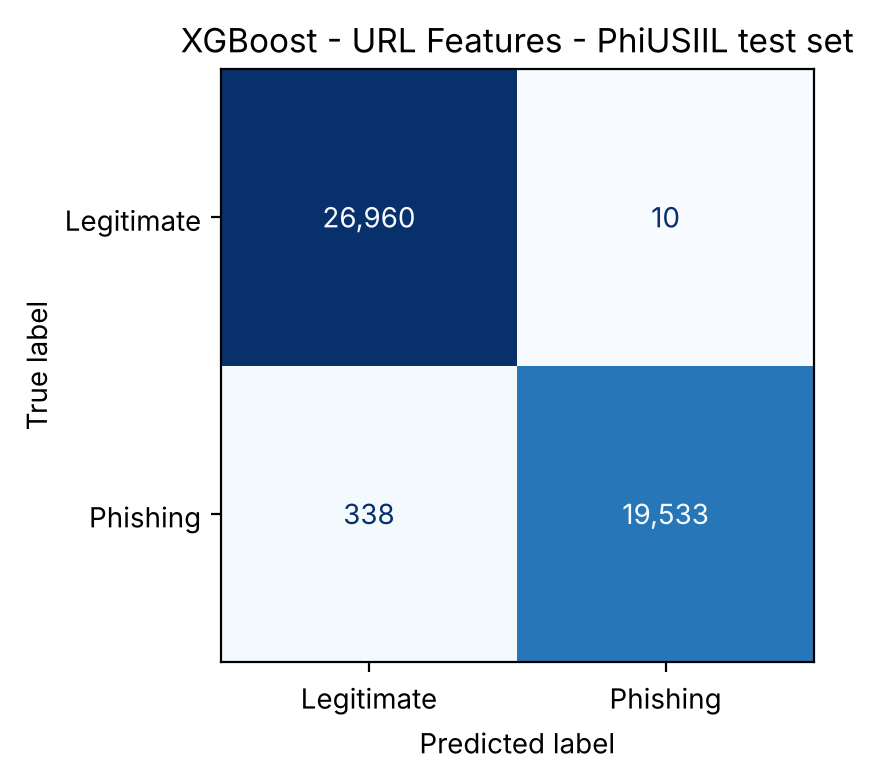

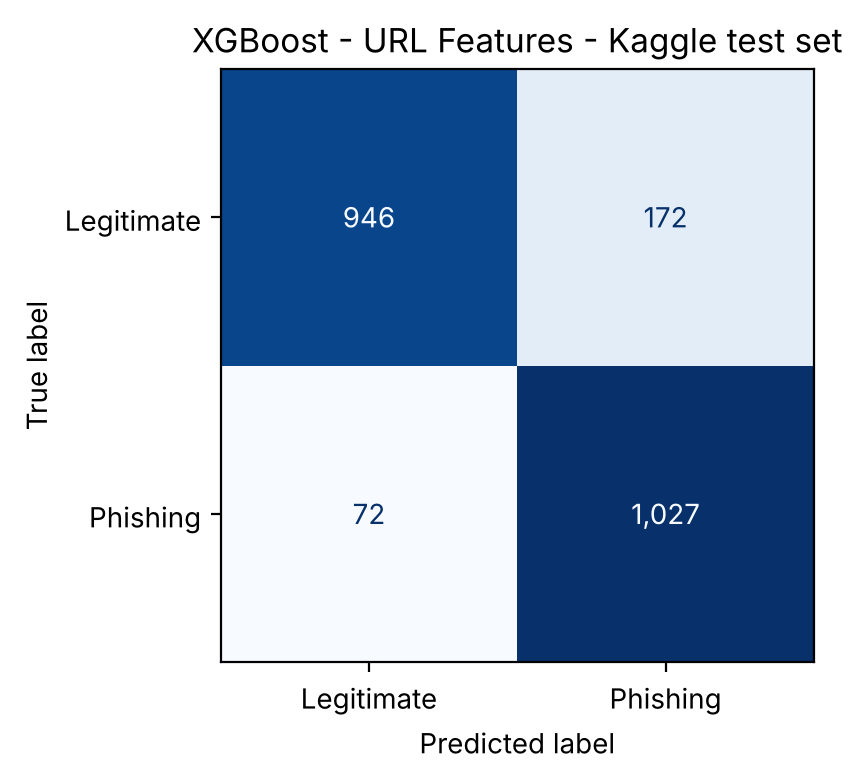

In [15]:
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    plot_confusion_matrix(y_url_test, url_model.predict(X_url_test), f"{MODEL_NAME} - URL Features - {test_name}")

### Did the 22 New URL Features Help?

We train the same model on both datasets again, but only with the 18 URL features from `02_preprocessing.ipynb`, and compare it with the model that uses all 40 URL features.

In [16]:
base_url_features = list(extract_url_features("example.com"))
base_url_model = fit_with_weights(clone(url_best_model), X_url_train[base_url_features], y_url_train, url_weights)

url_feature_results = {}
for test_name, (X_url_test, y_url_test) in url_test_sets.items():
    url_feature_results[("18 URL features", test_name)] = evaluate_model(base_url_model, X_url_test[base_url_features], y_url_test)
    url_feature_results[("40 URL features", test_name)] = url_results[("Trained on both datasets", test_name)]

pd.DataFrame(url_feature_results).T.round(4)

,,Accuracy,Precision,Recall,F1,ROC-AUC
18 URL features,PhiUSIIL test set,0.9734,0.9978,0.9394,0.9677,0.9976
40 URL features,PhiUSIIL test set,0.9926,0.9995,0.9830,0.9912,0.9988
18 URL features,Kaggle test set,0.8512,0.8186,0.8990,0.8569,0.9341
40 URL features,Kaggle test set,0.8899,0.8565,0.9345,0.8938,0.9628


### Feature Importance

We show the 15 URL features the final Experiment 2 model used most.

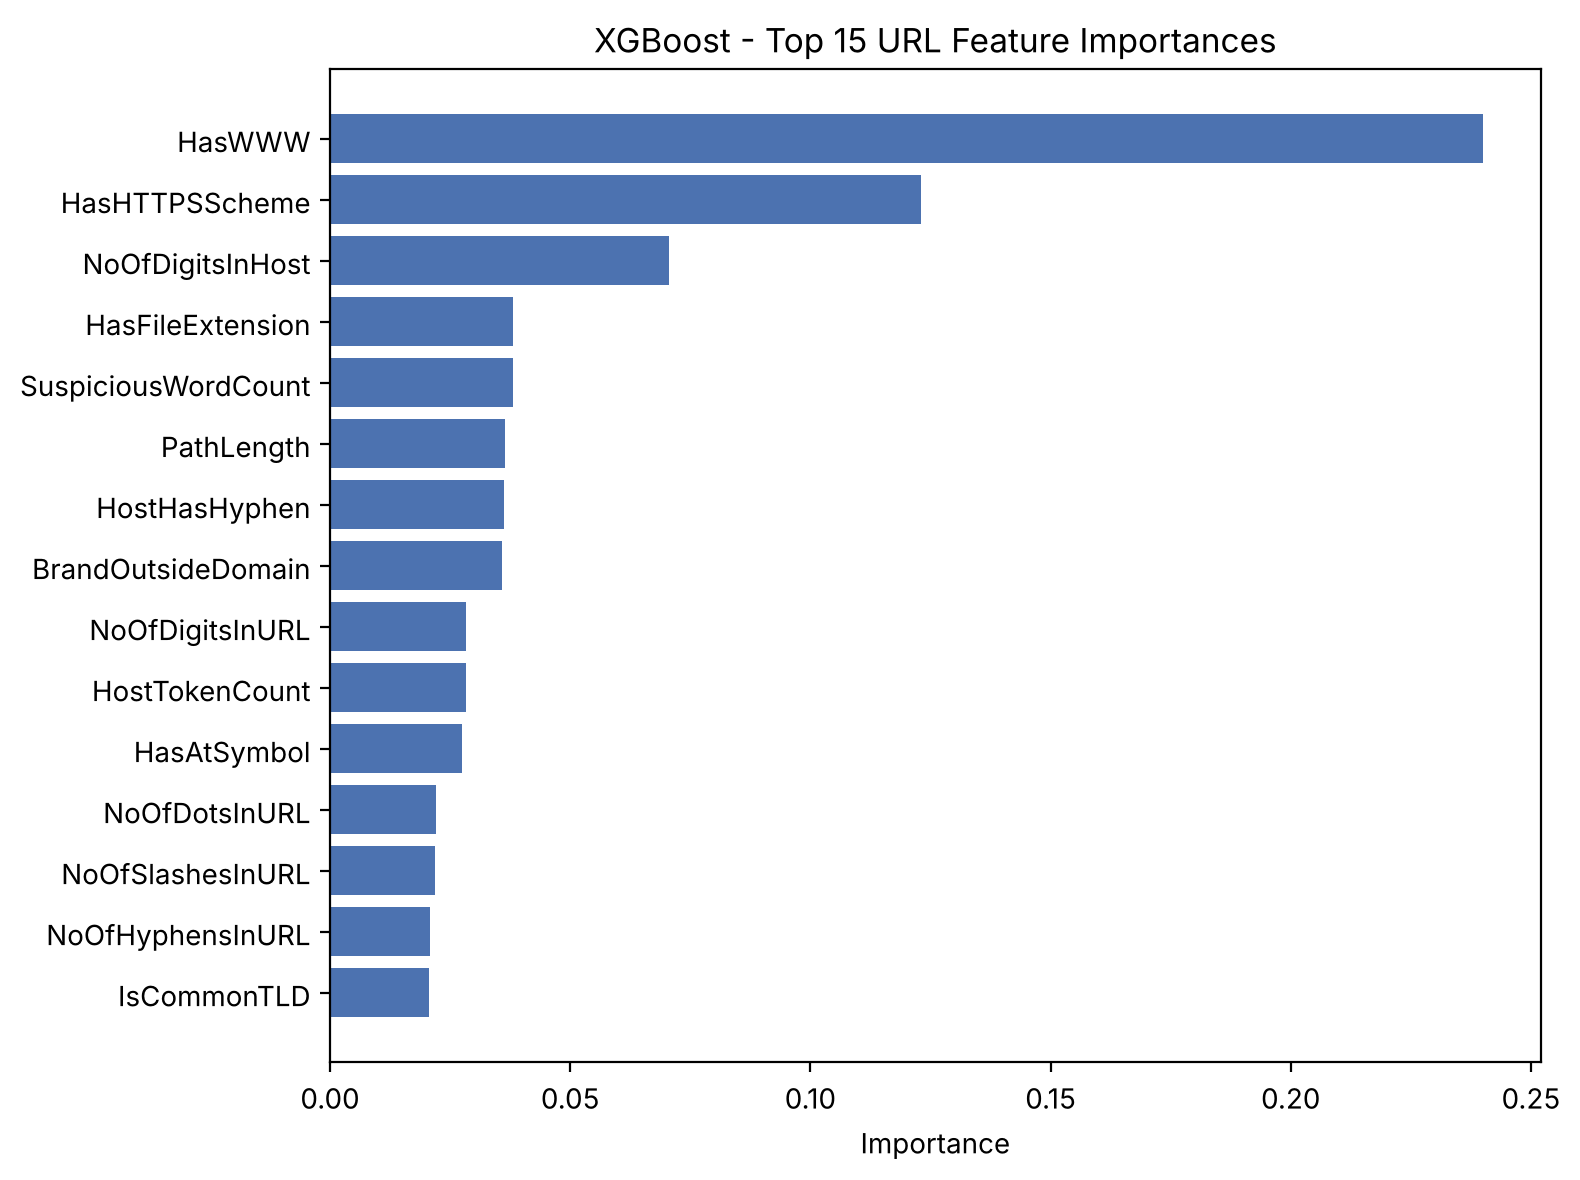

,Importance
HasWWW,0.2400
HasHTTPSScheme,0.1230
NoOfDigitsInHost,0.0707
HasFileExtension,0.0380
SuspiciousWordCount,0.0380
PathLength,0.0363
HostHasHyphen,0.0361
BrandOutsideDomain,0.0359
NoOfDigitsInURL,0.0283
HostTokenCount,0.0282


In [17]:
url_importance = pd.Series(url_model.feature_importances_, index=X_url_train.columns).sort_values(ascending=False)
top_url_features = url_importance.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_url_features.index[::-1], top_url_features.values[::-1], color="#4C72B0")
ax.set_title(f"{MODEL_NAME} - Top 15 URL Feature Importances")
ax.set_xlabel("Importance")
fig.tight_layout()

save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "xgboost_url_feature_importance.png", dpi=300)
plt.show()

top_url_features.round(4).to_frame("Importance")

### Does the Model Depend on `www` and HTTPS?

In PhiUSIIL, every legitimate URL starts with `www` and uses HTTPS, and the feature importance above shows that the model relies a lot on `HasWWW` and `HasHTTPSScheme`. So a legitimate website without `www` or HTTPS might look suspicious to the model.

To check how much the model depends on this, we remove `http://`, `https://` and `www.` from every URL before creating the features. This removes `HasWWW` and `HasHTTPSScheme`, and also removes this information from the other features (for example, `FullURLLength` no longer counts `https://www.`). We then train the same model with the same settings on both datasets and compare the scores.

In [18]:
X_clean_train, _, _, clean_test_sets = load_url_experiment(clean_urls=True)
clean_model = fit_with_weights(clone(url_best_model), X_clean_train, y_url_train, url_weights)

clean_results = {}
for test_name, (X_clean_test, y_clean_test) in clean_test_sets.items():
    clean_results[("With www and HTTPS", test_name)] = url_results[("Trained on both datasets", test_name)]
    clean_results[("Without www and HTTPS", test_name)] = evaluate_model(clean_model, X_clean_test, y_clean_test)

print(f"Features without www and HTTPS: {X_clean_train.shape[1]}")
pd.DataFrame(clean_results).T.round(4)

Features without www and HTTPS: 38


,,Accuracy,Precision,Recall,F1,ROC-AUC
With www and HTTPS,PhiUSIIL test set,0.9926,0.9995,0.9830,0.9912,0.9988
Without www and HTTPS,PhiUSIIL test set,0.8801,0.9525,0.7551,0.8424,0.9075
With www and HTTPS,Kaggle test set,0.8899,0.8565,0.9345,0.8938,0.9628
Without www and HTTPS,Kaggle test set,0.8710,0.8396,0.9145,0.8754,0.9505


## 6. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [19]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - Cross-validation - PhiUSIIL", **url_cv_results["PhiUSIIL Mean"].to_dict()},
    {"Experiment": "URL features - Cross-validation - Kaggle", **url_cv_results["Kaggle Mean"].to_dict()},
]

for (train_name, test_name), scores in url_results.items():
    row = {"Experiment": f"URL features - {train_name} - {test_name}", **scores}
    if train_name == "Trained on both datasets" and test_name == "PhiUSIIL test set":
        row["Train Time (s)"] = url_train_time
    results.append(row)

for (feature_name, test_name), scores in url_feature_results.items():
    if feature_name == "18 URL features":
        results.append({"Experiment": f"URL features - Trained on both datasets (18 URL features) - {test_name}", **scores})
for (version, test_name), scores in clean_results.items():
    if version == "Without www and HTTPS":
        results.append({"Experiment": f"URL features - Trained on both datasets (without www and HTTPS) - {test_name}", **scores})

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,XGBoost,Cross-validation,1.0000,1.0000,1.0000,1.0000,1.0000,NaN
1,XGBoost,Test set - All features,1.0000,1.0000,0.9999,0.9999,1.0000,2.8322
2,XGBoost,Test set - Original features only,1.0000,1.0000,0.9999,0.9999,1.0000,NaN
3,XGBoost,Test set - Without URLSimilarityIndex,0.9999,0.9999,0.9998,0.9998,1.0000,NaN
4,XGBoost,URL features - Cross-validation - PhiUSIIL,0.9921,0.9998,0.9816,0.9906,0.9985,NaN
5,XGBoost,URL features - Cross-validation - Kaggle,0.8922,0.8548,0.9429,0.8966,0.9659,NaN
6,XGBoost,URL features - Trained on PhiUSIIL only - PhiU...,0.9982,0.9996,0.9961,0.9979,0.9990,NaN
7,XGBoost,URL features - Trained on PhiUSIIL only - Kagg...,0.4957,0.4957,0.9991,0.6626,0.7210,NaN
8,XGBoost,URL features - Trained on both datasets - PhiU...,0.9926,0.9995,0.9830,0.9912,0.9988,4.7561
9,XGBoost,URL features - Trained on both datasets - Kagg...,0.8899,0.8565,0.9345,0.8938,0.9628,NaN


## 7. Findings

- **Test score:** XGBoost made only **2 mistakes out of 46,841 test URLs** (accuracy 99.996%). It never called a legitimate URL phishing (precision 100%), and it missed 2 of the 19,871 phishing URLs (recall 99.99%).
- **Stability:** The 5-fold cross-validation scores were almost exactly the same in every fold (standard deviation close to 0), so the result is stable and not a lucky split.
- **Best settings:** `max_depth = 4` and `learning_rate = 0.05`. Small, simple trees were enough, which also lowers the risk of overfitting.
- **Feature importance:** XGBoost depends almost completely on `URLSimilarityIndex` (about 98% of the importance). The next features, `LineOfCode` and `IsHTTPS`, matter much less.
- **New features:** Using only the original features gave the same score (2 mistakes). On this dataset the original features are already strong enough, so our new features did not change the result for XGBoost.
- **Without `URLSimilarityIndex`:** The model still reached 99.99% accuracy (6 mistakes). So even though it leans on this feature, it can still find phishing URLs well using the other features.
- **The 2 missed URLs** are phishing URLs that look like plain home pages (`http://www.lauglyhousebuyers.com` and `https://www.visitpietroburgo.com`). Most of our other models miss the same 2 URLs.

### Experiment 2: URL Features Only

- **Training on both datasets fixed the main problem.** When trained on PhiUSIIL only, the model scored 99.8% on the PhiUSIIL test set but only **49.6% on the Kaggle test set**, because it called almost every Kaggle URL phishing. After adding the Kaggle training part with sample weights, it scored **89.0% on the Kaggle test set** (F1 0.894, ROC-AUC 0.963) and still **99.3% on the PhiUSIIL test set** (F1 0.991).
- **Kaggle test set:** out of 1,118 legitimate URLs, 172 were called phishing (false alarms), and out of 1,099 phishing URLs, 72 were missed (recall 93.5%). So the model catches most phishing URLs, but it still gives some false alarms on legitimate inner pages.
- **PhiUSIIL test set:** only 10 false alarms, but 338 of 19,871 phishing URLs were missed (recall 98.3%). Learning from Kaggle URLs made the model a little less strict, so it misses a few more PhiUSIIL phishing URLs than the PhiUSIIL-only model.
- **Hyperparameter tuning:** we tuned again for URL features, using the average F1 on PhiUSIIL and Kaggle URLs in cross-validation. The best settings were `max_depth = 6`, `learning_rate = 0.1` and 600 trees. Deeper trees (8) were better on PhiUSIIL but worse on Kaggle, which shows they learn PhiUSIIL-only patterns. More trees helped because URL features carry less information than the 69 features in Experiment 1.
- **Stability:** the cross-validation F1 was 0.991 ± 0.001 for PhiUSIIL URLs and 0.897 ± 0.008 for Kaggle URLs, close to the test scores, so the test result is reliable.
- **The 22 new URL features helped a lot.** With only the 18 URL features from `02_preprocessing.ipynb`, the model scored 85.1% on Kaggle and 97.3% on PhiUSIIL. With all 40 features, it scored 89.0% and 99.3%. The new features make up about half (53%) of the total feature importance.
- **Feature importance:** `HasWWW` (24%, a new feature) and `HasHTTPSScheme` (12%) are the most important, followed by `NoOfDigitsInHost` (7%).
- **Without `www` and HTTPS:** when we removed `http://`, `https://` and `www.` from every URL, the Kaggle score dropped only a little (89.0% → 87.1%), but the PhiUSIIL score dropped a lot (99.3% → 88.0%), mainly because the model missed many more phishing URLs (recall 98.3% → 75.5%). So on Kaggle URLs the model mostly uses other patterns, but in PhiUSIIL many phishing URLs look exactly like legitimate home pages except for `www` and HTTPS. These two signals are useful in both datasets, so we keep them. But a legitimate website without `www` or HTTPS is more likely to get a false alarm, which is a limitation of the model and the datasets.